# Matplotlib – 4 przykłady z galerii

Dla każdego: **najpierw oryginalny schemat** z [galerii Matplotlib 3.1.3](https://matplotlib.org/3.1.3/gallery/index.html), **potem zmodyfikowana wersja** (nowe dane + cechy graficzne).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

---
# 1. Grouped bar chart with labels

Źródło: https://matplotlib.org/3.1.3/gallery/lines_bars_and_markers/barchart.html

### Oryginał z galerii

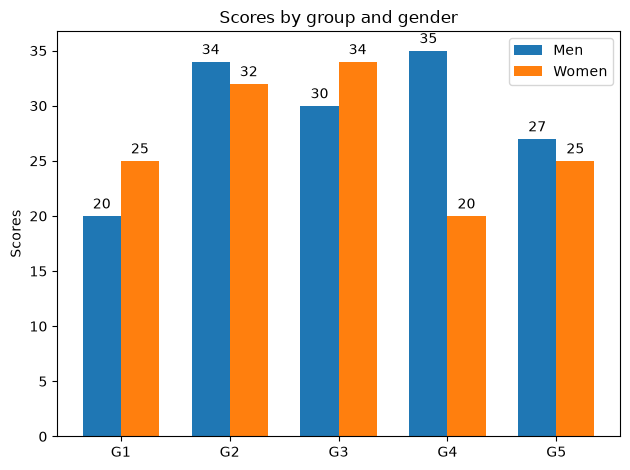

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

labels = ['G1', 'G2', 'G3', 'G4', 'G5']
men_means = [20, 34, 30, 35, 27]
women_means = [25, 32, 34, 20, 25]

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, men_means, width, label='Men')
rects2 = ax.bar(x + width/2, women_means, width, label='Women')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Scores')
ax.set_title('Scores by group and gender')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()


def autolabel(rects):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        ax.annotate('{}'.format(height),
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')


autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()

### Wersja zmodyfikowana

**Zmiany:** dane → temperatura wody lato/jesień per stacja; figsize `(11,6)`; kolory `#1b6ca8` / `#c45c26`; polskie etykiety; grid; ukryte spines.

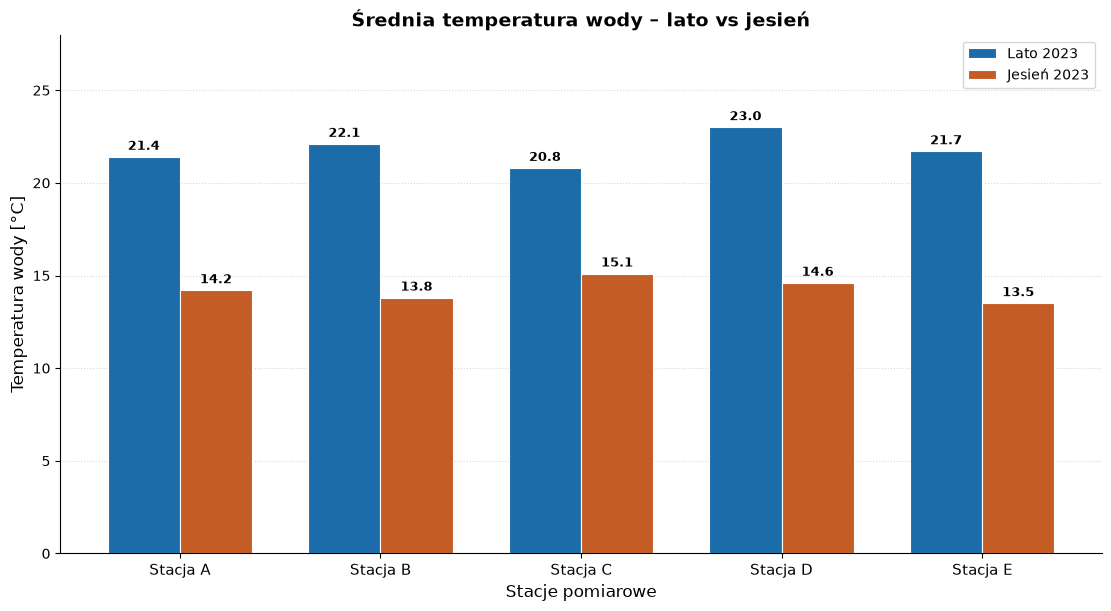

In [3]:
stations = ('Stacja A', 'Stacja B', 'Stacja C', 'Stacja D', 'Stacja E')
temp_means = {
    'Lato 2023': (21.4, 22.1, 20.8, 23.0, 21.7),
    'Jesień 2023': (14.2, 13.8, 15.1, 14.6, 13.5),
}
x = np.arange(len(stations))
width = 0.36
multiplier = 0

fig, ax = plt.subplots(figsize=(11, 6), layout='constrained')
colors = ['#1b6ca8', '#c45c26']

for (season, measurement), color in zip(temp_means.items(), colors):
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=season,
                   color=color, edgecolor='white', linewidth=0.8)
    ax.bar_label(rects, padding=3, fmt='%.1f', fontsize=9, fontweight='bold')
    multiplier += 1

ax.set_ylabel('Temperatura wody [°C]', fontsize=12)
ax.set_xlabel('Stacje pomiarowe', fontsize=12)
ax.set_title('Średnia temperatura wody – lato vs jesień', fontsize=14, fontweight='bold')
ax.set_xticks(x + width / 2, stations, fontsize=11)
ax.set_ylim(0, 28)
ax.legend(loc='upper right', frameon=True, edgecolor='#ccc')
ax.spines[['top', 'right']].set_visible(False)
ax.yaxis.grid(True, linestyle=':', alpha=0.5)
ax.set_axisbelow(True)
plt.show()

---
# 2. Stacked Bar Graph

Źródło: https://matplotlib.org/3.1.3/gallery/lines_bars_and_markers/bar_stacked.html

### Oryginał z galerii

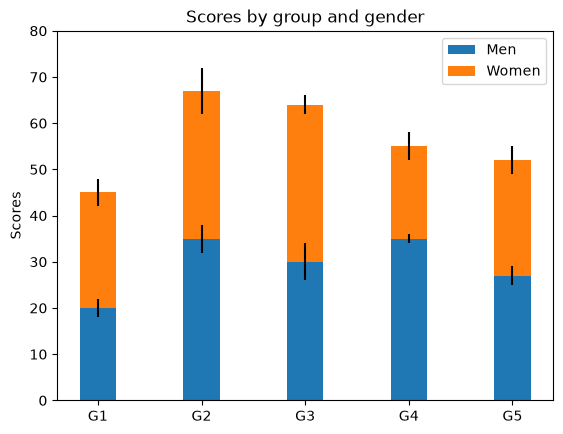

In [4]:
import numpy as np
import matplotlib.pyplot as plt

N = 5
menMeans = (20, 35, 30, 35, 27)
womenMeans = (25, 32, 34, 20, 25)
menStd = (2, 3, 4, 1, 2)
womenStd = (3, 5, 2, 3, 3)
ind = np.arange(N)    # the x locations for the groups
width = 0.35       # the width of the bars: can also be len(x) sequence

p1 = plt.bar(ind, menMeans, width, yerr=menStd)
p2 = plt.bar(ind, womenMeans, width,
             bottom=menMeans, yerr=womenStd)

plt.ylabel('Scores')
plt.title('Scores by group and gender')
plt.xticks(ind, ('G1', 'G2', 'G3', 'G4', 'G5'))
plt.yticks(np.arange(0, 81, 10))
plt.legend((p1[0], p2[0]), ('Men', 'Women'))

plt.show()

### Wersja zmodyfikowana

**Zmiany:** dane → NH₄-N / NO₃-N / DON w miesiącach; 3 warstwy; kolory earth-tone; figsize; polskie etykiety; bez error bars.

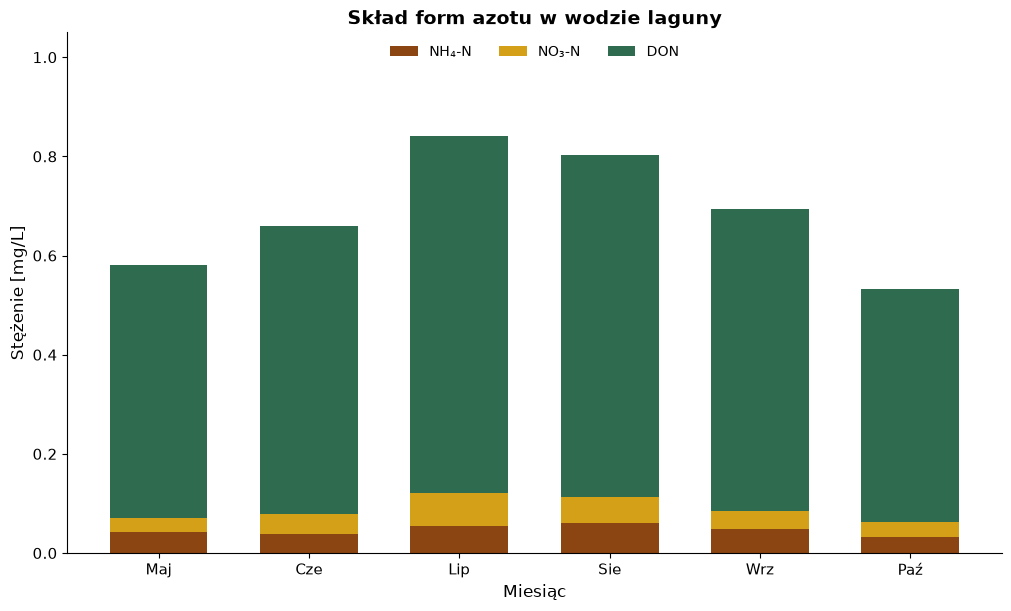

In [5]:
months = ['Maj', 'Cze', 'Lip', 'Sie', 'Wrz', 'Paź']
nh4 = np.array([0.042, 0.038, 0.055, 0.061, 0.048, 0.033])
no3 = np.array([0.028, 0.041, 0.067, 0.052, 0.036, 0.029])
don = np.array([0.51, 0.58, 0.72, 0.69, 0.61, 0.47])

fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
ax.bar(months, nh4, label='NH₄-N', color='#8b4513', width=0.65)
ax.bar(months, no3, bottom=nh4, label='NO₃-N', color='#d4a017', width=0.65)
ax.bar(months, don, bottom=nh4 + no3, label='DON', color='#2e6b4f', width=0.65)

ax.set_ylabel('Stężenie [mg/L]', fontsize=12)
ax.set_xlabel('Miesiąc', fontsize=12)
ax.set_title('Skład form azotu w wodzie laguny', fontsize=14, fontweight='bold')
ax.legend(ncols=3, loc='upper center', frameon=False, fontsize=10)
ax.tick_params(labelsize=11)
ax.spines[['top', 'right']].set_visible(False)
ax.set_ylim(0, 1.05)
plt.show()

---
# 3. Scatter plot with histograms

Źródło: https://matplotlib.org/3.1.3/gallery/lines_bars_and_markers/scatter_hist.html

### Oryginał z galerii

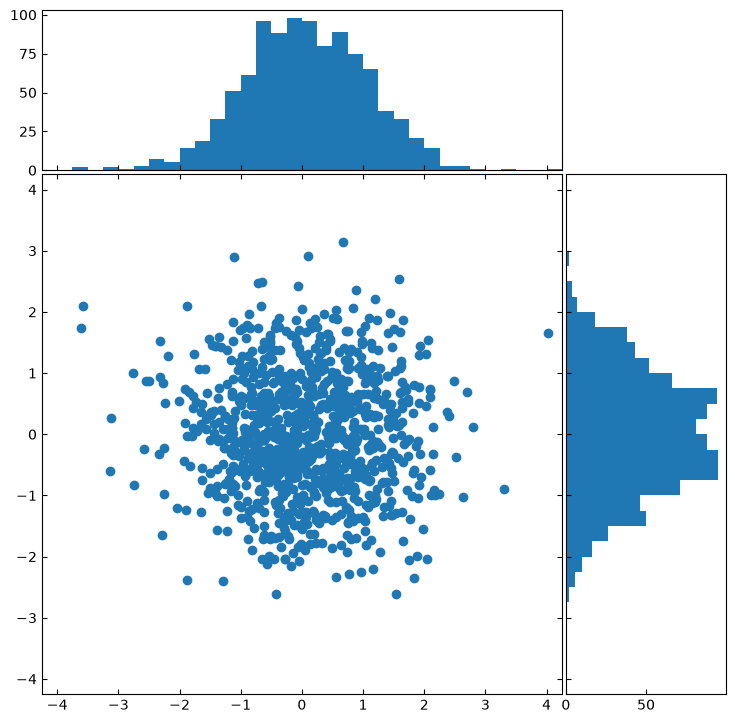

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Fixing random state for reproducibility
np.random.seed(19680801)

# the random data
x = np.random.randn(1000)
y = np.random.randn(1000)

# definitions for the axes
left, width = 0.1, 0.65
bottom, height = 0.1, 0.65
spacing = 0.005

rect_scatter = [left, bottom, width, height]
rect_histx = [left, bottom + height + spacing, width, 0.2]
rect_histy = [left + width + spacing, bottom, 0.2, height]

# start with a rectangular Figure
plt.figure(figsize=(8, 8))

ax_scatter = plt.axes(rect_scatter)
ax_scatter.tick_params(direction='in', top=True, right=True)
ax_histx = plt.axes(rect_histx)
ax_histx.tick_params(direction='in', labelbottom=False)
ax_histy = plt.axes(rect_histy)
ax_histy.tick_params(direction='in', labelleft=False)

# the scatter plot:
ax_scatter.scatter(x, y)

# now determine nice limits by hand:
binwidth = 0.25
lim = np.ceil(np.abs([x, y]).max() / binwidth) * binwidth
ax_scatter.set_xlim((-lim, lim))
ax_scatter.set_ylim((-lim, lim))

bins = np.arange(-lim, lim + binwidth, binwidth)
ax_histx.hist(x, bins=bins)
ax_histy.hist(y, bins=bins, orientation='horizontal')

ax_histx.set_xlim(ax_scatter.get_xlim())
ax_histy.set_ylim(ax_scatter.get_ylim())

plt.show()

### Wersja zmodyfikowana

**Zmiany:** dane → temp vs O₂ (realistyczna korelacja); kolor punktów = głębokość; własne kolory histogramów; polskie etykiety; gridspec.

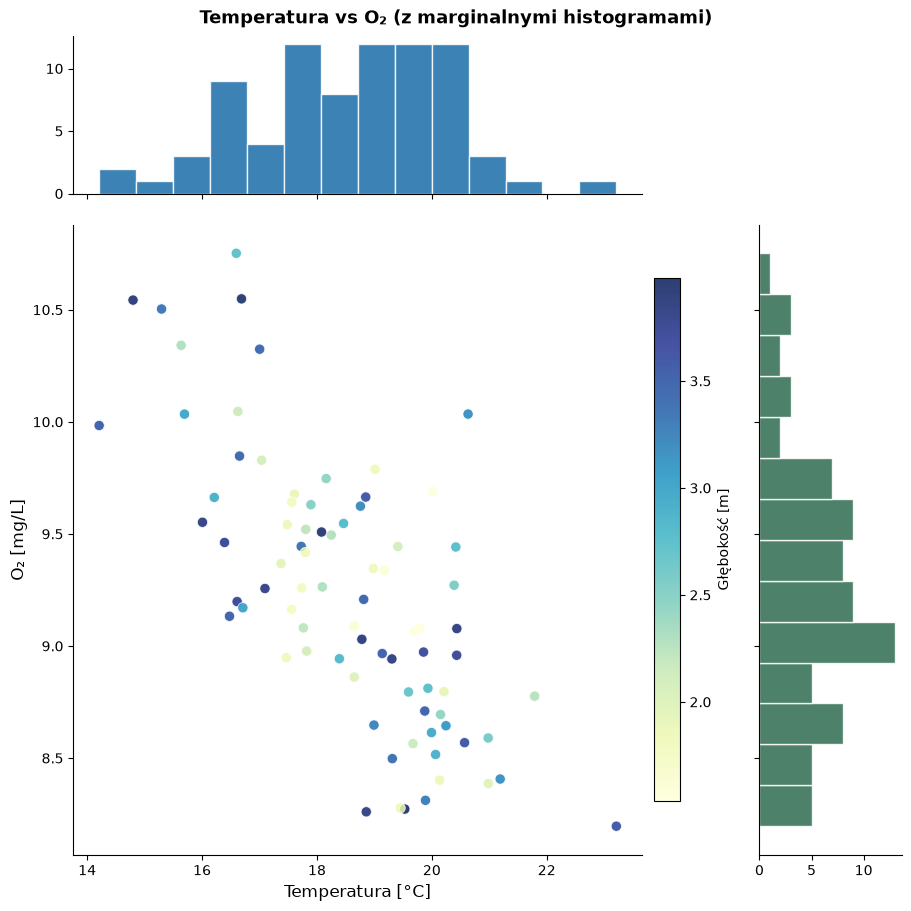

In [7]:
rng = np.random.default_rng(42)
n = 80
temp = rng.normal(18.5, 2.2, n)
o2 = 14.5 - 0.28 * temp + rng.normal(0, 0.45, n)
depth = rng.uniform(1.5, 4.0, n)

fig = plt.figure(figsize=(9, 9), layout='constrained')
gs = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4),
                      wspace=0.05, hspace=0.05)
ax = fig.add_subplot(gs[1, 0])
ax_histx = fig.add_subplot(gs[0, 0], sharex=ax)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax)

sc = ax.scatter(temp, o2, c=depth, cmap='YlGnBu', s=55, alpha=0.85,
                edgecolors='white', linewidths=0.6)
cbar = fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.046)
cbar.set_label('Głębokość [m]', fontsize=10)

ax.set_xlabel('Temperatura [°C]', fontsize=12)
ax.set_ylabel('O₂ [mg/L]', fontsize=12)
ax.spines[['top', 'right']].set_visible(False)

ax_histx.hist(temp, bins=14, color='#1b6ca8', edgecolor='white', alpha=0.85)
ax_histy.hist(o2, bins=14, orientation='horizontal', color='#2e6b4f', edgecolor='white', alpha=0.85)
ax_histx.tick_params(labelbottom=False)
ax_histy.tick_params(labelleft=False)
for a in (ax_histx, ax_histy):
    a.spines[['top', 'right']].set_visible(False)

fig.suptitle('Temperatura vs O₂ (z marginalnymi histogramami)', fontsize=13, fontweight='bold')
plt.show()

---
# 4. Creating annotated heatmaps

Źródło: https://matplotlib.org/3.1.3/gallery/images_contours_and_fields/image_annotated_heatmap.html

*(A simple categorical heatmap)*

### Oryginał z galerii

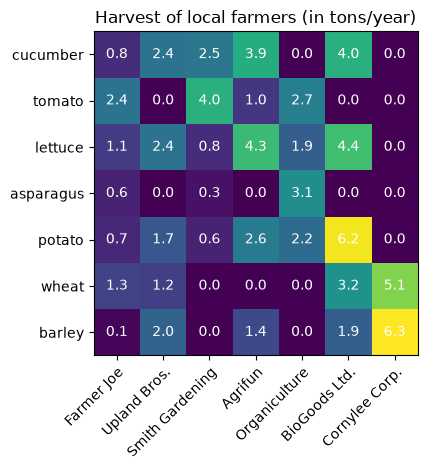

In [8]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

vegetables = ["cucumber", "tomato", "lettuce", "asparagus",
              "potato", "wheat", "barley"]
farmers = ["Farmer Joe", "Upland Bros.", "Smith Gardening",
           "Agrifun", "Organiculture", "BioGoods Ltd.", "Cornylee Corp."]

harvest = np.array([[0.8, 2.4, 2.5, 3.9, 0.0, 4.0, 0.0],
                    [2.4, 0.0, 4.0, 1.0, 2.7, 0.0, 0.0],
                    [1.1, 2.4, 0.8, 4.3, 1.9, 4.4, 0.0],
                    [0.6, 0.0, 0.3, 0.0, 3.1, 0.0, 0.0],
                    [0.7, 1.7, 0.6, 2.6, 2.2, 6.2, 0.0],
                    [1.3, 1.2, 0.0, 0.0, 0.0, 3.2, 5.1],
                    [0.1, 2.0, 0.0, 1.4, 0.0, 1.9, 6.3]])

fig, ax = plt.subplots()
im = ax.imshow(harvest)

# We want to show all ticks...
ax.set_xticks(np.arange(len(farmers)))
ax.set_yticks(np.arange(len(vegetables)))
# ... and label them with the respective list entries
ax.set_xticklabels(farmers)
ax.set_yticklabels(vegetables)

# Rotate the tick labels and set their alignment.
plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
         rotation_mode="anchor")

# Loop over data dimensions and create text annotations.
for i in range(len(vegetables)):
    for j in range(len(farmers)):
        text = ax.text(j, i, harvest[i, j],
                       ha="center", va="center", color="w")

ax.set_title("Harvest of local farmers (in tons/year)")
fig.tight_layout()
plt.show()

### Wersja zmodyfikowana

**Zmiany:** dane → SS [mg/L] sezon × strefa laguny; colormap `YlOrRd`; colorbar z etykietą; kontrastowe adnotacje (białe/ciemne); polskie etykiety; figsize.

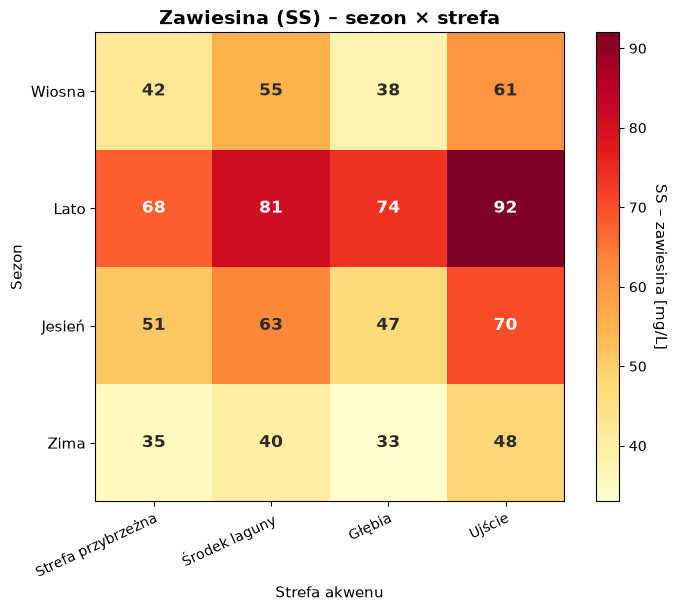

In [9]:
seasons = ['Wiosna', 'Lato', 'Jesień', 'Zima']
zones = ['Strefa przybrzeżna', 'Środek laguny', 'Głębia', 'Ujście']
harvest = np.array([
    [42, 55, 38, 61],
    [68, 81, 74, 92],
    [51, 63, 47, 70],
    [35, 40, 33, 48],
])

fig, ax = plt.subplots(figsize=(9, 6), layout='constrained')
im = ax.imshow(harvest, cmap='YlOrRd')
cbar = ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.set_ylabel('SS – zawiesina [mg/L]', rotation=-90, va='bottom', fontsize=11)

ax.set_xticks(np.arange(len(zones)), labels=zones, fontsize=10)
ax.set_yticks(np.arange(len(seasons)), labels=seasons, fontsize=11)
plt.setp(ax.get_xticklabels(), rotation=25, ha='right', rotation_mode='anchor')

for i in range(len(seasons)):
    for j in range(len(zones)):
        val = harvest[i, j]
        txt_color = 'white' if val > 65 else '#2c2a27'
        ax.text(j, i, f'{val}', ha='center', va='center',
                color=txt_color, fontsize=12, fontweight='bold')

ax.set_title('Zawiesina (SS) – sezon × strefa', fontsize=14, fontweight='bold')
ax.set_xlabel('Strefa akwenu', fontsize=11)
ax.set_ylabel('Sezon', fontsize=11)
plt.show()